# Deutsch's Algorithm

In [49]:
!pip install qiskit
!pip install qiskit[visualization]
!pip install qiskit_aer -simulator
!pip install matplotlib 
!pip install pylatexenc 


Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

no such option: -s


In [50]:
def daut_oracle(qc,f_type):
    if f_type == 1:
        pass
    elif f_type == 2:
        qc.x(1)
    elif f_type == 3:
        qc.cx(0,1)
    elif f_type == 4:
        qc.x(0)
        qc.cx(0,1)

In [51]:
def deus_algo(f_type):
    qc = qsk.QuantumCircuit(2,1)
    qc.x(1)
    qc.h(0)
    qc.h(1)
    daut_oracle(qc,f_type)
    qc.h(0)
    qc.measure(0,0)
    return qc

In [52]:
import qiskit as qsk

In [53]:
from qiskit import transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram
from matplotlib import pyplot as plt


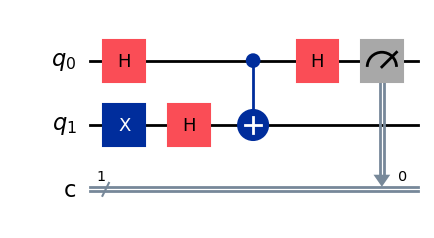

In [54]:
qc = deus_algo(3)
qc.draw(output="mpl")


In [55]:
simulator = Aer.get_backend('qasm_simulator')
compiled_circuit = qsk.transpile(qc, simulator)
job = simulator.run(compiled_circuit)
result = job.result()
counts = result.get_counts(qc)

In [56]:
print(result)   


Result(backend_name='qasm_simulator', backend_version='0.18.2', job_id='2f67a54d-515a-4f8b-88f6-e9612ac0ed64', success=True, results=[ExperimentResult(shots=1024, success=True, meas_level=2, data=ExperimentResultData(counts={'0x1': 1024}), header={'creg_sizes': [['c', 1]], 'global_phase': 0.0, 'memory_slots': 1, 'n_qubits': 2, 'name': 'circuit-50', 'qreg_sizes': [['q', 2]], 'metadata': {}}, status=DONE, seed_simulator=2969744177, metadata={'time_taken': 0.000910696, 'num_bind_params': 1, 'parallel_state_update': 2, 'parallel_shots': 1, 'required_memory_mb': 1, 'input_qubit_map': [[1, 1], [0, 0]], 'method': 'statevector', 'device': 'CPU', 'num_qubits': 2, 'sample_measure_time': 0.000228898, 'active_input_qubits': [0, 1], 'num_clbits': 1, 'remapped_qubits': False, 'runtime_parameter_bind': False, 'max_memory_mb': 12975, 'noise': 'ideal', 'measure_sampling': True, 'batched_shots_optimization': False, 'fusion': {'applied': False, 'max_fused_qubits': 5, 'threshold': 14, 'enabled': True}}, t

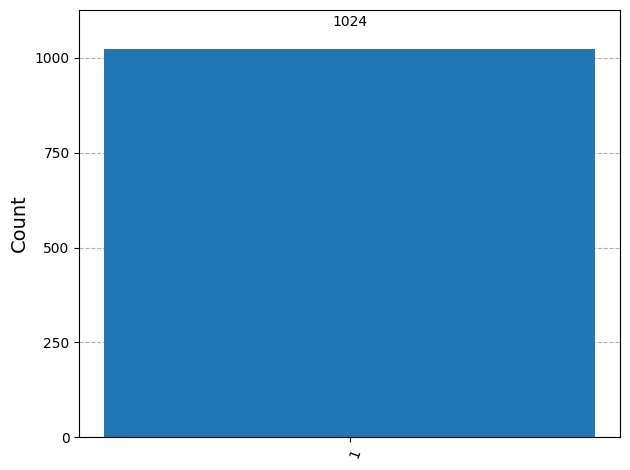

In [47]:
plot_histogram(counts)
